In [2]:
%reset -f
%load_ext autoreload
%autoreload 2

import os
import time
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import glob
import math
from sklearn.linear_model import LinearRegression
import figurefirst as fifi
sys.path.append('../utils_2')
import figure_functions as ff
import utility
from pybounds import SlidingEmpiricalObservabilityMatrix, SlidingFisherObservability, colorline
sys.path.append('../model')
from drone_model_with_PWM import DroneSimulator
from drone_model_with_PWM import DroneModel
from drone_model_with_PWM import DroneParameters
sys.path.append('../EKF')
from ekf import ekf as EKF
import pynumdiff
from scipy import signal
sys.path.append('../trajectories')
from trajectory_gen import TrajectoryGenerator
from IPython.display import display,SVG
# from drone_model_body_level import DroneSimulator

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
wind_sensor = 'real' #['real', 'simulated']
condition = 'flying' #['walking', 'flying']
motif = 'neg_X' #['p2p', 'p2p_con_yaw', 'acc', 'sine']
path = '/home/austinlopez/Drone_AFRL/CSV'
all_files = glob.glob(path + "/" + motif + "/*.csv")
data = {}
for filename in all_files:
    df = pd.read_csv(filename,index_col=None,header=0)
    # set data dictionary based on filename after the string '__'
    key = filename.split('__')[-1].split('.')[0]
    # remove the next 18 characters from the key name then replace '_slash_' with '/'
    key = key[6:].replace('_slash_', '/')
    data[key] = df

for key in data.keys():
    print(key)

mavros/rc/in
optic_flow
drone/rpy/degrees
mavros/imu/data
optic_flow/global/mean/x
mavros/local_position/pose
optic_flow/global/mean/y
trisonica
optic_flow/wind_sensor/mean/x
drone/rpy/radians
optic_flow/camera/mean/y
optic_flow/wind_sensor/mean/y
mavros/rc/out
optic_flow/camera/mean/x
trisonica_body_level
trisonica_global


dt: 0.025063276290893555 seconds


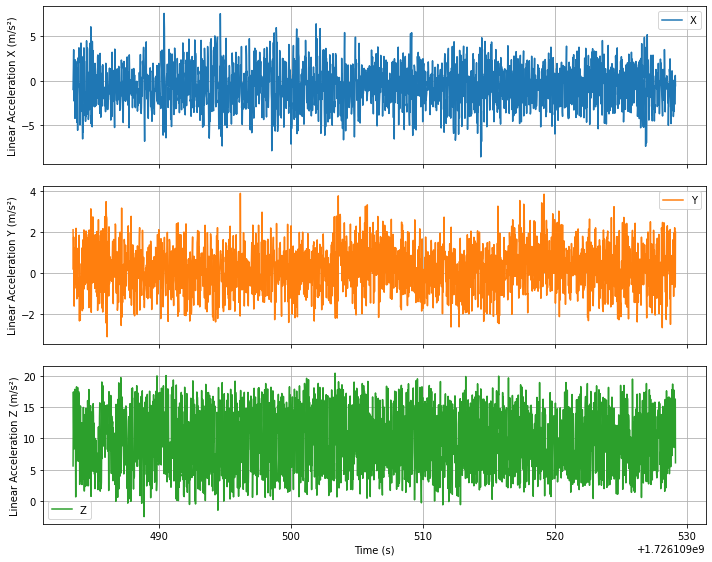

In [12]:
data['mavros/imu/data']
dt = data['mavros/imu/data']['rosbagTimestamp'][1]/1e9 - data['mavros/imu/data']['rosbagTimestamp'][0]/1e9
print(f"dt: {dt} seconds")
imu_time = data['mavros/imu/data']['rosbagTimestamp']/1e9
linear_acceleration_x = data['mavros/imu/data']['x.2']
linear_acceleration_y = data['mavros/imu/data']['y.2']
linear_acceleration_z = data['mavros/imu/data']['z.2']
# Plotting the linear acceleration data on 3 subplots
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axs[0].plot(imu_time, linear_acceleration_x, label='X', color='tab:blue')
axs[0].set_ylabel('Linear Acceleration X (m/s²)')
axs[0].legend()
axs[0].grid()
axs[1].plot(imu_time, linear_acceleration_y, label='Y', color='tab:orange')
axs[1].set_ylabel('Linear Acceleration Y (m/s²)')
axs[1].legend()
axs[1].grid()
axs[2].plot(imu_time, linear_acceleration_z, label='Z', color='tab:green')
axs[2].set_ylabel('Linear Acceleration Z (m/s²)')
axs[2].set_xlabel('Time (s)')
axs[2].legend()
axs[2].grid()
plt.tight_layout()
plt.show()

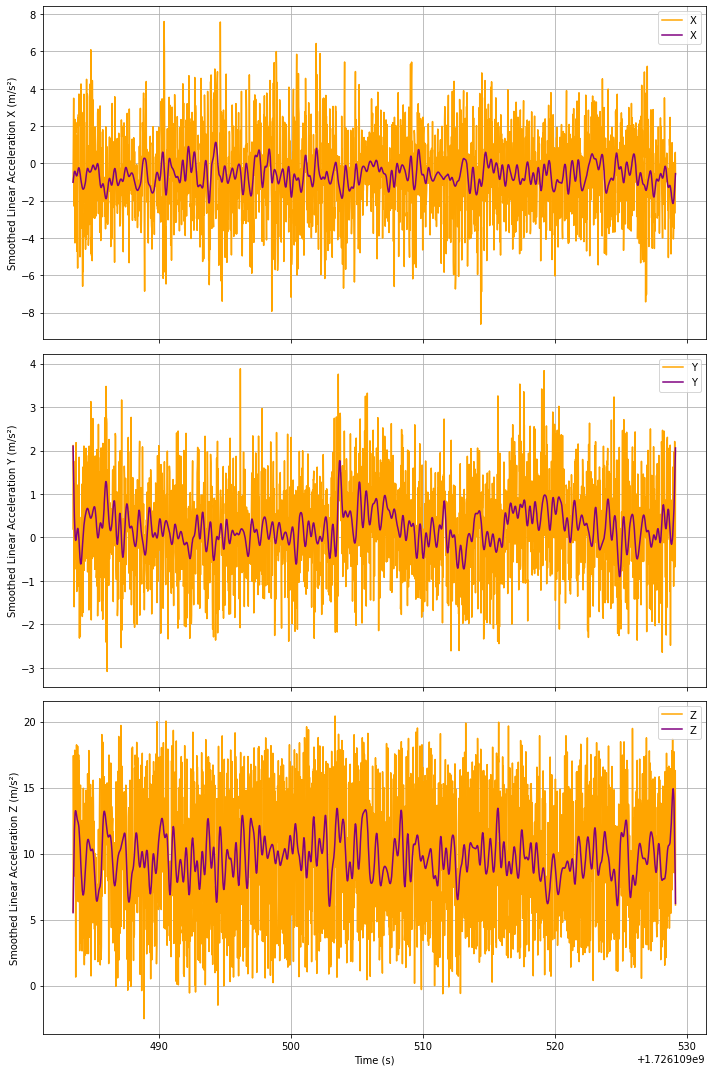

In [14]:
smooth_params = [4, 0.1]
linear_acceleration_x_hat, linear_acceleration_x_dot = pynumdiff.smooth_finite_difference.butterdiff(linear_acceleration_x, dt, smooth_params, options={'iterate': False})
linear_acceleration_y_hat, linear_acceleration_y_dot = pynumdiff.smooth_finite_difference.butterdiff(linear_acceleration_y, dt, smooth_params, options={'iterate': False})
linear_acceleration_z_hat, linear_acceleration_z_dot = pynumdiff.smooth_finite_difference.butterdiff(linear_acceleration_z, dt, smooth_params, options={'iterate': False})
# Plotting the smoothed linear acceleration data on 3 subplots
fig, axs = plt.subplots(3, 1, figsize=(10, 15), sharex=True)
axs[0].plot(imu_time, linear_acceleration_x, label='X', color='orange')
axs[0].plot(imu_time, linear_acceleration_x_hat, label='X', color='purple')
axs[0].set_ylabel('Smoothed Linear Acceleration X (m/s²)')
axs[0].legend()
axs[0].grid()
axs[1].plot(imu_time, linear_acceleration_y, label='Y', color='orange')
axs[1].plot(imu_time, linear_acceleration_y_hat, label='Y', color='purple')
axs[1].set_ylabel('Smoothed Linear Acceleration Y (m/s²)')
axs[1].legend()
axs[1].grid()
axs[2].plot(imu_time, linear_acceleration_z, label='Z', color='orange')
axs[2].plot(imu_time, linear_acceleration_z_hat, label='Z', color='purple')
axs[2].set_ylabel('Smoothed Linear Acceleration Z (m/s²)')
axs[2].set_xlabel('Time (s)')
axs[2].legend()
axs[2].grid()
plt.tight_layout()
plt.show()